In [29]:
import numpy as np
import pandas as pd
import os
from pathlib import Path
import joblib

from matplotlib import pyplot as plt
from sklearn import datasets
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from gene_thesaurus import GeneThesaurus

In [36]:
DATASETS_PATH = "/home/mariya/Data/pallas/mlomix_datasets"

TRAIN_DATASET_PATH = os.path.join(DATASETS_PATH, "train-gex")
X_train_path = os.path.join(TRAIN_DATASET_PATH, "features.gex.csv")
y_train_path = os.path.join(TRAIN_DATASET_PATH, "labels.csv")

TEST_DATASET_PATH = os.path.join(DATASETS_PATH, "cal-and-test-gex")
X_test_path = os.path.join(TEST_DATASET_PATH, "features.gex.csv")
y_test_path = os.path.join(TEST_DATASET_PATH, "labels.csv")

MODELS_PATH = "/home/mariya/Data/pallas/models/gex"
rf_model_path = os.path.join(MODELS_PATH, "rf_model.pkl")

base_dir = Path.cwd()
features_path = base_dir / "output" / "selected_features.3.txt"
random_seed = 42


output_dir = "/home/mariya/Data/pallas/models/gex/dt"

# Make output directory if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

In [31]:
# Read in rf model
rf_model = joblib.load(rf_model_path)

In [3]:
# Read in selected features
with open(features_path, "r") as f:
    selected_features = [line.strip() for line in f.readlines()]
print(f"Number of selected features: {len(selected_features)}")

Number of selected features: 196


In [4]:
# Read in X_train and y_train
X_train = pd.read_csv(X_train_path, index_col=0)

# Subset X_train to selected features
X_train = X_train[selected_features]
y_train = pd.read_csv(y_train_path, index_col=0)

X_train, y_train

(             ENSG00000184507  ENSG00000079102  ENSG00000248329  \
 id                                                               
 SJHBBBM2BBR        -0.948134        -1.093703        -1.093703   
 SJHBBBM2GV5        -0.988235        -1.093703        -0.594273   
 SJHBBBM39BT        -1.093703        -1.093703        -0.987930   
 SJHBBBM4JQZ        -1.093703        -1.093703        -1.093703   
 SJHBBBM4X52        -1.093703        -1.051299        -0.895005   
 ...                      ...              ...              ...   
 16-367             -1.093703         0.428460        -1.093703   
 16-372             -1.045965        -0.936247        -1.093703   
 16-373             -1.093703        -1.093703        -1.093703   
 16-374             -1.031594        -0.864327        -1.093703   
 16-376             -1.019390        -0.885430        -1.093703   
 
              ENSG00000101115  ENSG00000145794  ENSG00000105642  \
 id                                                         

In [37]:
# Read in test data
X_test = pd.read_csv(X_test_path, index_col=0)
y_test = pd.read_csv(y_test_path, index_col=0)

# Subset X_test to selected features
X_test = X_test[selected_features]
X_test, y_test

(             ENSG00000184507  ENSG00000079102  ENSG00000248329  \
 id                                                               
 SJHBBBM4PX3        -1.009419        -1.139177        -1.139177   
 SJHBBBM5PY5        -1.139177        -1.139177        -1.139177   
 SJHBBBM5TXY        -1.052304        -1.139177        -0.678568   
 SJHBBBM67H6        -1.062484        -1.139177        -1.139177   
 SJHBBBN9RDM        -1.032888        -1.139177        -1.139177   
 ...                      ...              ...              ...   
 16-335             -1.038952        -1.139177        -1.139177   
 16-338             -0.877979        -1.121756        -1.139177   
 16-343             -1.066091        -1.139177        -1.139177   
 16-346              6.701331        -1.006708        -1.139177   
 16-350              0.389281         0.440512         0.269102   
 
              ENSG00000101115  ENSG00000145794  ENSG00000105642  \
 id                                                         

In [ ]:
feature_names = X_train.columns.tolist()
# Translate with gene thesaurus
gt = GeneThesaurus()
translated = gt.translate_genes(feature_names,
                               source="ensembl_id", target="symbol")
translated


In [21]:
# Get translated values to list. it is a dict
translated_list = [translated[feature] for feature in feature_names]
translated_list

['NUTM1',
 'RUNX1T1',
 'APELA',
 'SALL4',
 'MEGF10',
 'KCNN1',
 'HOXB6',
 'PLAAT5',
 'ANKS1B',
 'NDST3',
 'HOXB5',
 'PBX1',
 'PTPRZ1',
 'ADGRF1',
 'HLCS',
 'MEIS1',
 'CPA4',
 'HDAC9',
 'WNT9A',
 'SALL1',
 'PDC',
 'ARHGEF12',
 'KLHL14',
 'DGKI',
 'DLX3',
 'WNT7B',
 'ABL1',
 'IQCJ',
 'KRTAP17-1',
 'CAVIN1',
 'SLC22A31',
 'IGF2BP1',
 'CHST8',
 'KRT17',
 'TRPC4',
 'PCDH17',
 'VAT1L',
 'SETD4',
 'EPN2',
 'DDIT4L',
 'SESN1',
 'TTC28',
 'WNT16',
 'FOLR1',
 'DAPK1',
 'SKIDA1',
 'CCL17',
 'ELOVL4',
 'CUX2',
 'DTD1',
 'CACNA1H',
 'HLF',
 'CHST6',
 'MSLN',
 'TFPI',
 'LGSN',
 'TTC3',
 'ASB13',
 'LMX1B',
 'EVPL',
 'CRYGD',
 'LIPH',
 'SPRED1',
 'NAP1L2',
 'FCRLA',
 'UNCX',
 'TRHDE',
 'TDRP',
 'KLF15',
 'PCDH19',
 'KIF16B',
 'TTC16',
 'ARHGAP4',
 'GREB1',
 'KIF12',
 'CLIC5',
 'CYP2S1',
 'SLC25A4',
 'AGAP1',
 'ATXN1',
 'KBTBD11',
 'CNTNAP5',
 'COL6A5',
 'FHIT',
 'PPM1F',
 'HOXA9',
 'INPP5A',
 'ARG1',
 'EYA3',
 'RYR2',
 'HOOK1',
 'SOWAHD',
 'PAQR5',
 'IL7',
 'ACVR1C',
 'NDRG4',
 'LOXHD1',
 'FNBP1',
 'I

In [ ]:
# 1. Get the random forest's predictions on your training data
rf_predictions = rf_model.predict(X_train)
rf_predictions

array(['B-ALL, high hyperdiploid', 'B-ALL, ETV6::RUNX1',
       'B-ALL, ETV6::RUNX1', ..., 'T-ALL', 'B-ALL, high hyperdiploid',
       'B-ALL, BCR::ABL1-like'], shape=(3193,), dtype=object)

In [127]:
# 2. Train the decision tree to mimic those predictions
surrogate_tree = DecisionTreeClassifier(max_depth=10)  # keep it shallow for explainability
surrogate_tree.fit(X_train, rf_predictions)

# 3. Check how well the tree mimics the RF (fidelity score)
fidelity = surrogate_tree.score(X_test, rf_model.predict(X_test))

print(f"RF accuracy:        {rf_model.score(X_test, y_test):.2f}")
print(f"Surrogate fidelity: {fidelity:.2f}")
print(f"Surrogate accuracy: {surrogate_tree.score(X_test, y_test):.2f}")
print(f"Fidelity: {fidelity:.2f}")  # how often tree agrees with RF

RF accuracy:        0.91
Surrogate fidelity: 0.55
Surrogate accuracy: 0.53
Fidelity: 0.55


In [128]:
from sklearn.metrics import classification_report
print(classification_report(rf_model.predict(X_test), surrogate_tree.predict(X_test)))

                          precision    recall  f1-score   support

      AML, APL-PML::RARA       0.00      0.00      0.00         5
     AML, CBFA2T3::GLIS2       1.00      0.20      0.33        10
        AML, CBFB::MYH11       0.80      0.24      0.38        49
           AML, CEBPAalt       0.00      0.00      0.00        34
        AML, DEK::NUP214       0.67      0.20      0.31        10
             AML, ETV6-r       0.00      0.00      0.00         3
           AML, FUS::ERG       0.00      0.00      0.00         2
            AML, KAT6A-r       0.00      0.00      0.00         3
            AML, KMT2A-r       0.94      0.54      0.69       172
            AML, NPM1alt       0.83      0.16      0.27        62
            AML, NUP98-r       0.55      0.41      0.47        27
     AML, RUNX1::RUNX1T1       0.92      0.92      0.92       107
        B-ALL, BCR::ABL1       0.65      0.60      0.62        25
   B-ALL, BCR::ABL1-like       0.72      0.49      0.58       113
         

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

In [129]:
# Which classes have f1 over 0.7?
threshold = 0.7
classes_that_meet_threshold = []
report = classification_report(rf_model.predict(X_test), surrogate_tree.predict(X_test), output_dict=True)
for class_name, metrics in report.items():
    if class_name not in ['accuracy', 'macro avg', 'weighted avg']:
        f1_score = metrics['f1-score']
        if f1_score > threshold:
            classes_that_meet_threshold.append(class_name)

# print number of classes that meet threshold
print(f"Number of classes with F1-score above {threshold}: {len(classes_that_meet_threshold)}")
print(f"Classes with F1-score above {threshold}: {classes_that_meet_threshold}")


Number of classes with F1-score above 0.7: 7
Classes with F1-score above 0.7: ['AML, RUNX1::RUNX1T1', 'B-ALL, DUX4-r', 'B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1-like', 'B-ALL, KMT2A-r', 'B-ALL, TCF3::PBX1', 'B-ALL, high hyperdiploid']


/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

In [130]:
text_representation = tree.export_text(surrogate_tree, feature_names=translated_list)
print(text_representation)

|--- KCNN1 <= 5.56
|   |--- RUNX1T1 <= 4.82
|   |   |--- DACH1 <= 6.26
|   |   |   |--- KRTAP17-1 <= 0.51
|   |   |   |   |--- ADGRF1 <= 2.82
|   |   |   |   |   |--- APELA <= 1.65
|   |   |   |   |   |   |--- HOXB5 <= 3.03
|   |   |   |   |   |   |   |--- ANKS1B <= 3.62
|   |   |   |   |   |   |   |   |--- MSLN <= 4.01
|   |   |   |   |   |   |   |   |   |--- MEIS1 <= 6.17
|   |   |   |   |   |   |   |   |   |   |--- class: B-ALL, PAX5alt
|   |   |   |   |   |   |   |   |   |--- MEIS1 >  6.17
|   |   |   |   |   |   |   |   |   |   |--- class: B-ALL, KMT2A-r
|   |   |   |   |   |   |   |   |--- MSLN >  4.01
|   |   |   |   |   |   |   |   |   |--- LAMP5 <= 3.58
|   |   |   |   |   |   |   |   |   |   |--- class: AML, CBFB::MYH11
|   |   |   |   |   |   |   |   |   |--- LAMP5 >  3.58
|   |   |   |   |   |   |   |   |   |   |--- class: AML, KMT2A-r
|   |   |   |   |   |   |   |--- ANKS1B >  3.62
|   |   |   |   |   |   |   |   |--- class: B-ALL, TCF3::PBX1
|   |   |   |   |   |   |--- H

In [131]:
class_names = surrogate_tree.classes_
class_names

array(['AML, APL-PML::RARA', 'AML, CBFA2T3::GLIS2', 'AML, CBFB::MYH11',
       'AML, CEBPAalt', 'AML, DEK::NUP214', 'AML, ETV6-r',
       'AML, FUS::ERG', 'AML, KAT6A-r', 'AML, KMT2A-r', 'AML, NPM1alt',
       'AML, NUP98-r', 'AML, RUNX1::RUNX1T1', 'B-ALL, BCR::ABL1',
       'B-ALL, BCR::ABL1-like', 'B-ALL, DUX4-r', 'B-ALL, ETV6::RUNX1',
       'B-ALL, ETV6::RUNX1-like', 'B-ALL, HLF-r', 'B-ALL, IKZF1 N159Y',
       'B-ALL, KMT2A-r', 'B-ALL, MEF2D-r', 'B-ALL, MYC-r',
       'B-ALL, NUTM1-r', 'B-ALL, PAX5 P80R', 'B-ALL, PAX5alt',
       'B-ALL, TCF3::PBX1', 'B-ALL, ZNF384-r', 'B-ALL, high hyperdiploid',
       'B-ALL, hypodiploid', 'B-ALL, iAMP21', 'Non-leukemic', 'T-ALL'],
      dtype=object)

In [132]:
def get_class_paths(clf, feature_names, class_names, target_class):
    t = clf.tree_
    paths = []

    def recurse(node, path):
        if t.feature[node] == -2:  # leaf node
            class_label = class_names[t.value[node].argmax()]
            if class_label == target_class:
                paths.append(' AND '.join(path))
            return

        name = feature_names[t.feature[node]]
        threshold = t.threshold[node]
        recurse(t.children_left[node],  path + [f'{name} <= {threshold:.2f}'])
        recurse(t.children_right[node], path + [f'{name} > {threshold:.2f}'])

    recurse(0, [])
    return paths

for leukemia_class in classes_that_meet_threshold:
    print(f"---Paths for class: {leukemia_class}---")
    paths = get_class_paths(surrogate_tree, translated_list, class_names=class_names, target_class=leukemia_class)
    for p in paths:
        print(p)
    print("\n\n")

---Paths for class: AML, RUNX1::RUNX1T1---
KCNN1 <= 5.56 AND RUNX1T1 > 4.82 AND COL6A5 <= 4.06 AND IGSF9B <= 1.81
KCNN1 > 5.56 AND EPN2 <= 2.94 AND IGF2BP1 <= 6.70 AND WNT9A <= 4.24 AND TLCD5 > -0.59 AND ATP8A2 <= 0.97 AND FNBP1 <= 8.89 AND ZC2HC1A > -0.88 AND CACNA1H > 1.85



---Paths for class: B-ALL, DUX4-r---
KCNN1 <= 5.56 AND RUNX1T1 <= 4.82 AND DACH1 <= 6.26 AND KRTAP17-1 <= 0.51 AND ADGRF1 <= 2.82 AND APELA > 1.65 AND HOXA9 <= 3.23
KCNN1 <= 5.56 AND RUNX1T1 <= 4.82 AND DACH1 <= 6.26 AND KRTAP17-1 <= 0.51 AND ADGRF1 > 2.82 AND ABL1 <= 6.96 AND WNT9A <= 3.03 AND DDIT4L <= 4.85 AND LAMP5 <= 2.76 AND IGSF9B > 0.06
KCNN1 <= 5.56 AND RUNX1T1 <= 4.82 AND DACH1 <= 6.26 AND KRTAP17-1 <= 0.51 AND ADGRF1 > 2.82 AND ABL1 <= 6.96 AND WNT9A > 3.03 AND CLEC9A <= 5.26 AND DDIT4L > 6.44 AND DLX3 > -0.50
KCNN1 <= 5.56 AND RUNX1T1 <= 4.82 AND DACH1 <= 6.26 AND KRTAP17-1 > 0.51 AND DDIT4L <= 5.05 AND CCL17 <= 4.09 AND APELA > 4.03
KCNN1 <= 5.56 AND RUNX1T1 <= 4.82 AND DACH1 <= 6.26 AND KRTAP17-1 >

In [133]:
def print_class_paths(clf, feature_names, target_class):
    tree_text = tree.export_text(clf, feature_names=feature_names)
    lines = tree_text.split('\n')

    path = []
    for line in lines:
        depth = len(line) - len(line.lstrip('|'))

        # Trim path to current depth
        path = path[:depth]
        path.append(line.strip())

        # If this line is the target class, print the full path
        if f'class: {target_class}' in line:
            print('\n'.join(path))
            print('---')

for leukemia_class in classes_that_meet_threshold:
    print(f"---Paths for class: {leukemia_class}---")
    print_class_paths(surrogate_tree, translated_list, target_class=leukemia_class)

---Paths for class: AML, RUNX1::RUNX1T1---
|--- KCNN1 <= 5.56
|   |   |   |   |--- class: AML, RUNX1::RUNX1T1
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |   |   |--- class: AML, RUNX1::RUNX1T1
---
---Paths for class: B-ALL, DUX4-r---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |--- class: B-ALL, DUX4-r
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |   |   |   |--- class: B-ALL, DUX4-r
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |   |   |   |--- class: B-ALL, DUX4-r
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |--- class: B-ALL, DUX4-r
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |--- class: B-ALL, DUX4-r
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |   |   |   |--- class: B-ALL, DUX4-r
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |--- class: B-ALL, DUX4-r
---
---Paths for class: B-ALL, ETV6::RUNX1---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |   |   |--- class: B-ALL, ETV6::RUNX1
---
|--- KCNN1 <= 5.56
|   |   |   |   |   |   |   |--- cla

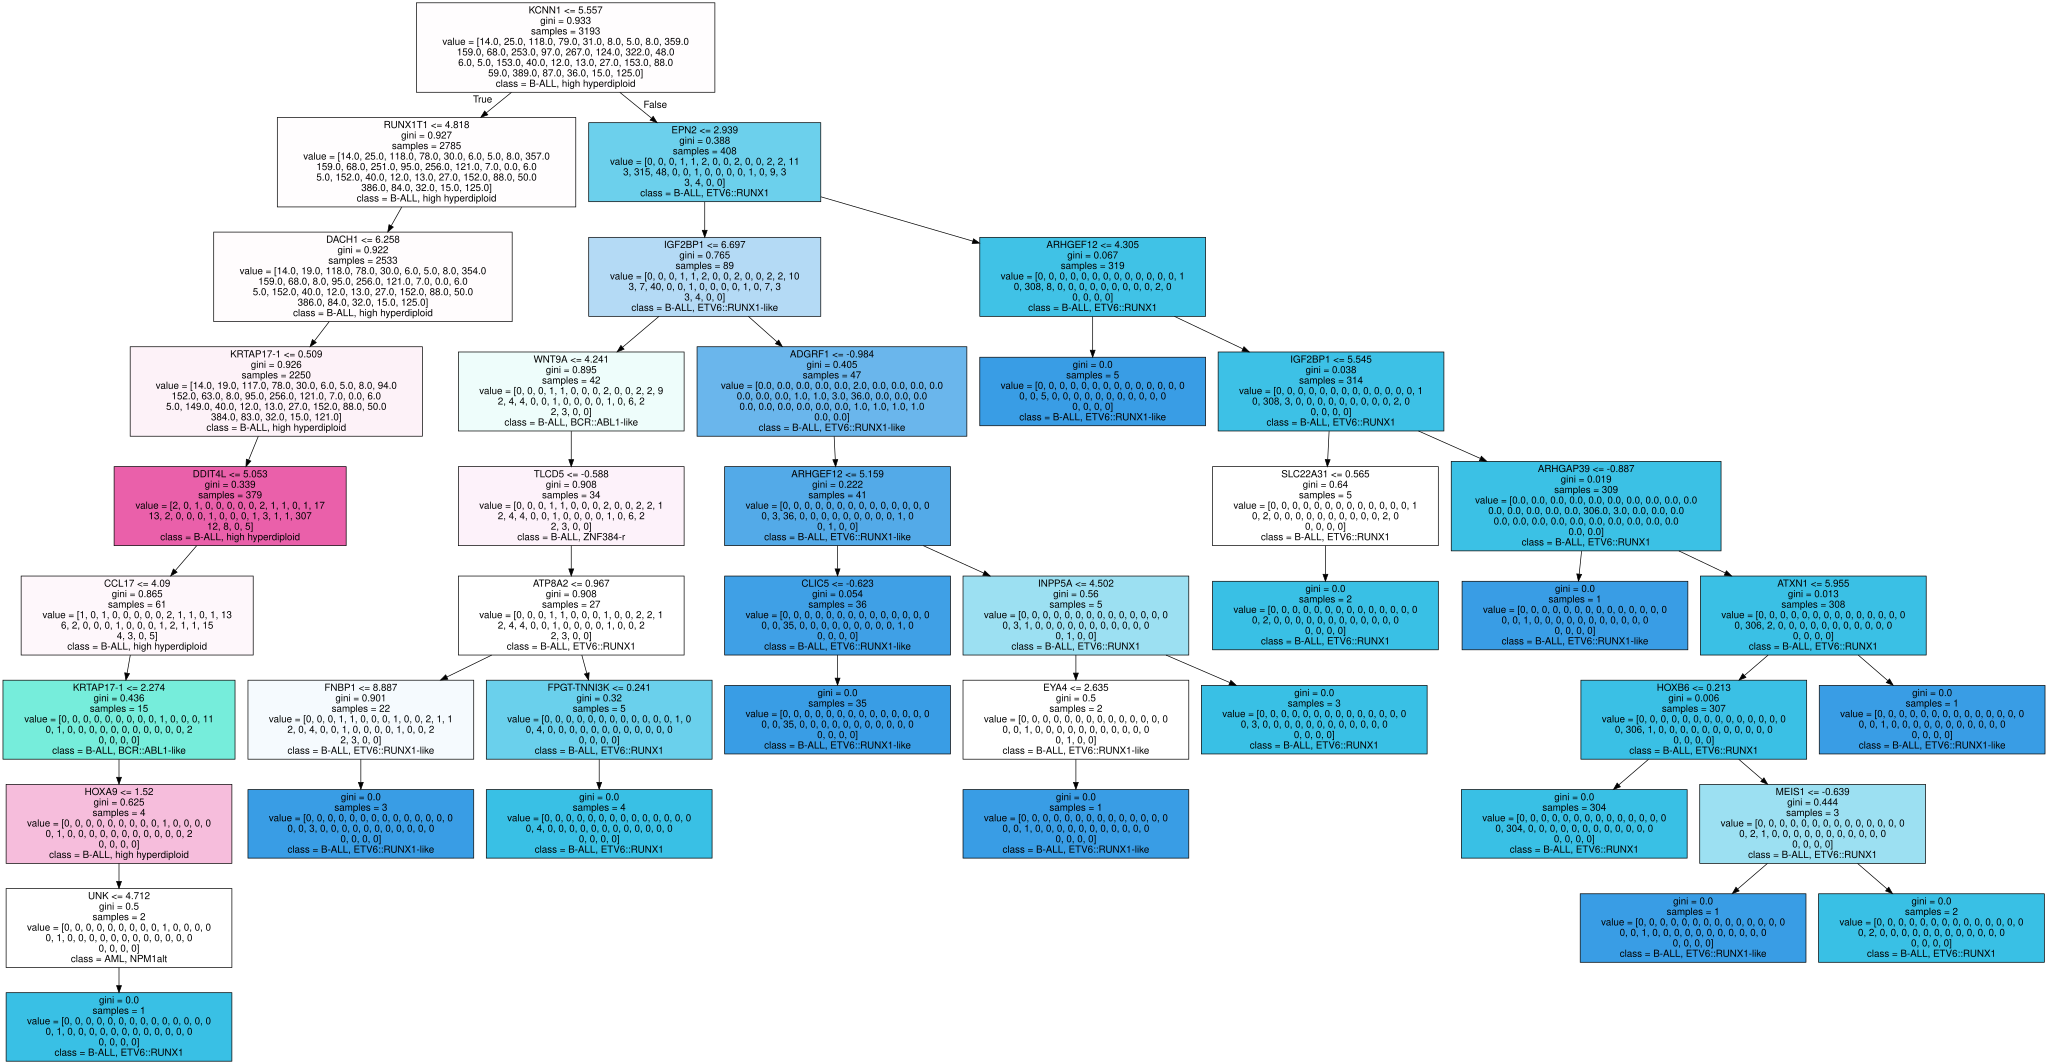

In [136]:
import graphviz
import re

def plot_class_subtree_graphviz(clf, feature_names, class_names, target_class):
    t = clf.tree_

    # normalize to list
    targets = [target_class] if isinstance(target_class, str) else target_class
    target_indices = set(list(class_names).index(c) for c in targets)

    def is_relevant(node):
        if t.feature[node] == -2:
            return t.value[node].argmax() in target_indices
        return is_relevant(t.children_left[node]) or is_relevant(t.children_right[node])

    relevant = set(i for i in range(t.node_count) if is_relevant(i))

    dot_data = tree.export_graphviz(clf, out_file=None,
                                    feature_names=feature_names,
                                    class_names=class_names,
                                    filled=True)

    filtered_lines = []
    for line in dot_data.split('\n'):
        node_match = re.match(r'^(\d+) \[', line)
        edge_match = re.match(r'^(\d+) -> (\d+)', line)

        if node_match:
            if int(node_match.group(1)) in relevant:
                filtered_lines.append(line)
        elif edge_match:
            if int(edge_match.group(1)) in relevant and int(edge_match.group(2)) in relevant:
                filtered_lines.append(line)
        else:
            filtered_lines.append(line)

    graph = graphviz.Source('\n'.join(filtered_lines), format="png")
    return graph


graph = plot_class_subtree_graphviz(surrogate_tree, translated_list, class_names, ['B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1-like'])
graph


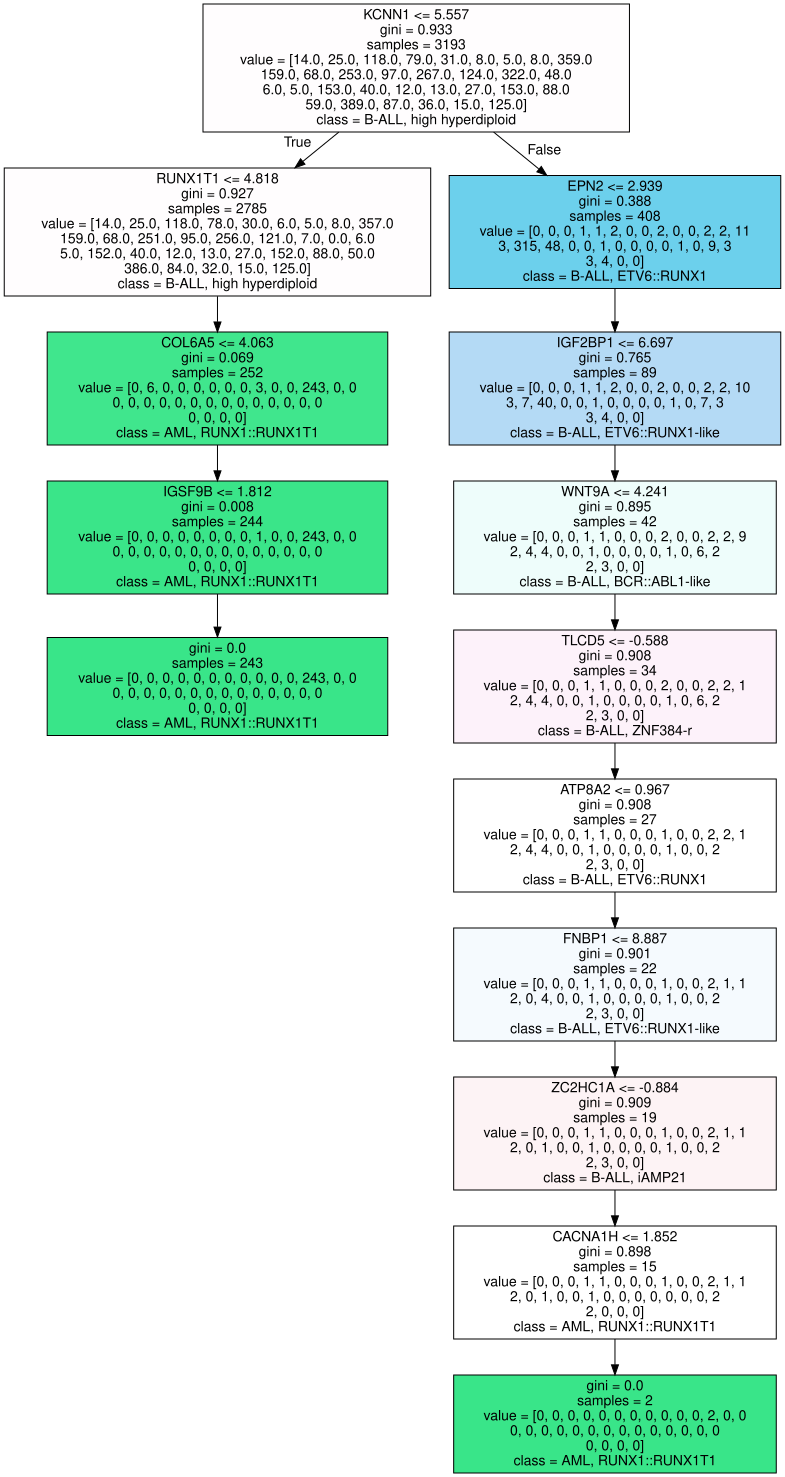

In [138]:

graph = plot_class_subtree_graphviz(surrogate_tree, translated_list, class_names, 'AML, RUNX1::RUNX1T1')
graph